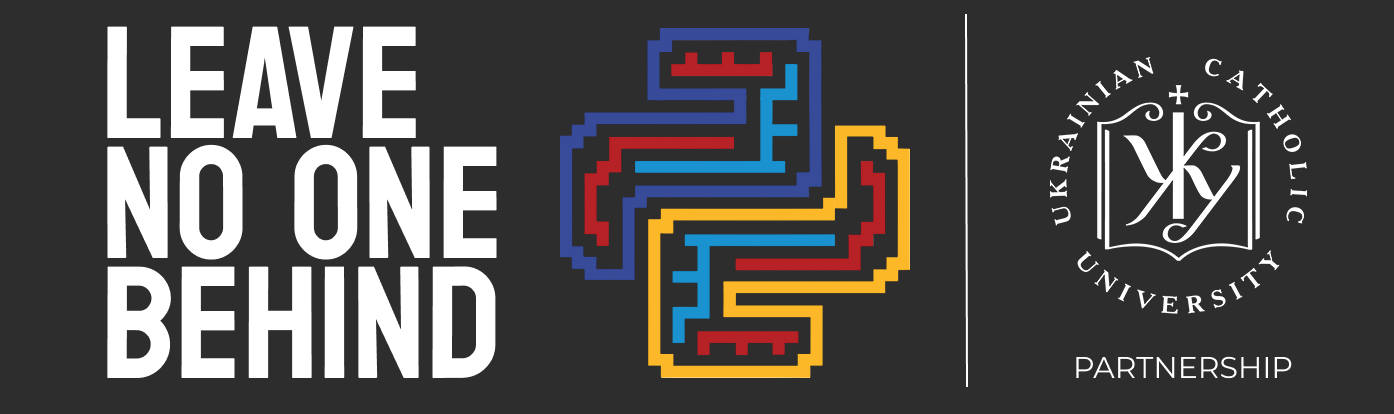

Перед Вами версія 1.0 навчальних матеріалів, що були створені командою Факультету прикладних наук Українського католицького університету в рамках освітнього проєкту ["Не залишити нікого осторонь"](https://www.facebook.com/leavenoonebehindpartnership/) 2024 року. Ми &mdash; Радомир Гусєв, Лідія Семсічко, Антон Валігурський, Максим Жук, Тетяна Захарченко &mdash; створювали його з любовʼю. Будемо вдячні, якщо наша праця буде завжди мати вказане авторство. Ліцензовано під [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

Чарівного Вам кодування!

# Стрічки, узагальнені типи в анотації

## Зміст

- [1. Стрічки як послідовності](#str-as-sequence)
- [2. Створення](#creation)
- [3. Стрічкове представлення об'єктів](#str-representation)
- [4. f-стрічки](#f-strings)
- [5. Незмінюваність](#immutability)
- [6. Функції для циклів](#loop-functions)
- [7. Методи стрічок](#str-methods)
- [8. Узагальнені типи в анотації](#generic-types)

<a href="str-as-sequence"></a>
## 1. Стрічки як послідовності

Стрічки, як і списки, кортежі та діапазони, є послідовностями.

У той час, як у списках та кортежах можуть бути будь-які елементи, стрічки фундаментально складаються із символів. Однак при виведенні вони виводяться як один суцільний текст (у Python навіть немає типу для збереження одиничного символа):

In [31]:
print("hello there!")

Оскільки стрічки, як і `range` насправді є послідовностями, їх можна передати при створенні `list` та подивитися, які є елементи:

In [32]:
print(list(range(4)))
print(list("hello there!"))

Аналогічно можна перетворювати в кортежі чи ітерувати по символах стрічок:

In [33]:
for ch in "hello there!":
    print(ch, end=" ")

tuple("hello there!")

h e l l o   t h e r e ! 

('h', 'e', 'l', 'l', 'o', ' ', 't', 'h', 'e', 'r', 'e', '!')

І як можна перевіряти на наявність елемента в послідовностях, так у стрічках можна дивитися, чи існує певний символ в ній:

In [34]:
print("h" in "hello there!")
print("x" in "hello there!")

Однак стрічки також додають можливість перевірок, чи входять цілі підстрічки (наприклад, слова, фрази тощо) в них. Наприклад:

In [35]:
print("hello" in "hello there!")
print("helo" in "hello there!")

<a href="creation"></a>
## 2. Створення

Найпростіший спосіб створити стрічку – це, звісно, записати текст у лапках (як-от `"hello, world!"` чи `'hello, world!'`). Однак є й багато інших. Наприклад, додати існуючі стрічки чи повторити одну стрічку багато разів:

In [36]:
print("hello" * 3)
print("hello" + " there")

Якщо не ставити знак `+`, до речі, то стрічки все одно з'єднаються. Таке теоретично може бути корисно, наприклад, для перенесення рядка:

In [37]:
print("it is a very long string which should be definitely split " +
      "into several rows")
print("it is a very long string which should be definitely split "
      "into several rows")

Однак все ж краще явно вказувати конкатенацію через `+`, коли захочеться таке робити, адже такий синтаксис може збивати з пантелику! Ми й розказуємо, аби в майбутньому у вас не виникало плутанини, коли хтось випадково таке напише.

Для створення багаторядкових стрічок можна використати потрійні лапки (одинарні чи двійні):

In [38]:
print("""hello
         there""")
print('''hello
world!''')

Або ж використовувати одинарні лапки, а замість нових рядочків писати `\n`:

In [39]:
print("hello\n    there")
print('hello\nworld!')

`\n` - це приклад "керувальної послідовності" (escape sequence). Зворотна коса риска каже, аби наступний символ не сприймався так, як він сприймається зазвичай. Таким чином у `\n` вона каже, аби `n` сприймалося як новий ряжок (newline).

З іншими символами вона може по-іншому змінювати їхнє значення. Наприклад, зазвичай лапки означають кінець стрічки. А що як хочеться усередині стрічки написати лапки як символ? `"He said "Hi""` - це Python сприйме як стрічка `"He said "`, стрічка `""` та якийсь вираз `Hi`:

In [40]:
print("He said "Hi"")

SyntaxError: invalid syntax. Perhaps you forgot a comma? (2283503455.py, line 1)

Один зі способів - це використати інший тип лапок:

In [41]:
print('He said "Hi"')

He said "Hi"


Однак все стає складніше, якщо потрібно використати кілька типів лапок в одному рядку:

In [42]:
print("He didn't say "Hi"")

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3383387848.py, line 1)

Для таких і ще складніших випадків можна з допомогою `\` змінити значення лапок на просто текст:

In [43]:
print('He didn\'t say "Hi"')

He didn't say "Hi"


А якщо ж захочеться вивести власне символ зворотної косої риски, то можна використати `\\`: перша коса риска скаже, аби друга не сприймалася як керуючий символ, а сприймалася як стрічка косої риски.

In [44]:
print("\\ дозволяє писати різні лапки: \"'")

\ дозволяє писати різні лапки: "'


Є ще багато керуючих послідовностей. Більше дізнатися можна тут: https://docs.python.org/3/reference/lexical_analysis.html#escape-sequences

Якщо в стрічці не планується використовувати спеціальні послідовності, як-от `\n`, то Python дозволяє вимкнути всі такі послідовності для написання стрічки. Для цього варто скористатися синтаксисом `r"<стрічка>"` (такі конструкції називають raw string literals або сирі (необроблені) стрічкові літерали):

In [45]:
print(r"hello \the\re'")

hello \the\re'


<a href="str-representation"></a>
## 3. Стрічкове представлення об'єктів

Більшість типів змінних вміють перетворюватися в стрічки. Наприклад, при виведенні якоїсь змінної `x` через `print` насправді спершу виконується `str(x)`, після чого виводиться стрічкове представлення. Тобто, можна сказати, кожного разу виконується таке:

In [46]:
x = 3
print(x)
print(str(x)) # Те ж саме
print(range(4))
print(str(range(4))) # Те ж саме

3
3
range(0, 4)
range(0, 4)


In [47]:
str([1, 2, 3]) + str(range(5)) + str({"a": 1, "b": 2})

"[1, 2, 3]range(0, 5){'a': 1, 'b': 2}"

Навіть об'єкти функцій виводять певну інформацію при виклику `str` на них (зверніть увагу, що виводимо `str(some_function)`, а не `str(some_function())`. У другому випадку вивело би `None` - адже вивело би результат виконання функції!)

In [48]:
def some_function():
    ...

str(some_function)

'<function some_function at 0x7fce5d7d0a40>'

<a href="f-strings"></a>
## 4. f-стрічки

Для об'єднання кількох стрічок можна використовувати `+`, як ми знаємо. Однак коли таких стрічок багато чи коли об'єднувати потрібно не лише зі стрічками, робити це через конкатенацію стає складно:

In [49]:
"string, " + str(14) + " - integer and dict: " + str({1: 2, 3: 4})

'string, 14 - integer and dict: {1: 2, 3: 4}'

Саме тому додали можливість використовувати f-стрічки, про які ви вже скоріш за все чули. У найпростішому вигляді вони просто дозволяють об'єднати кілька значень в одну стрічку, записуючи вирази у фігурних дужках:

In [50]:
f"string, {14} - integer and dict: {{1: 2, 3: 4}}"

'string, 14 - integer and dict: {1: 2, 3: 4}'

Однак в них є багато іншого функціоналу. Наприклад, вирівнювання тексту до `n` (як-от `5`) символів:

In [51]:
string = "abc"
print(f"|{string:>5}|{15-2:>5}|")

|  abc|   13|


У синтаксисі `{<вираз>:>5}`:
- `<вираз>` - назва змінної, аритметичні операції, виклик функції чи якийсь інший вираз,
- `:` - показує, що далі буде спеціальний синтаксис,
- `>` каже, що потрібно вирівняти цей вираз до `n` знаків, вирівнюючи справа (додаючи пропуски зліва), де `n` - це число після `>`
    > Якщо перед `>` поставити певний символ, то вирівнювати буде не пропусками, а тим символом.<br>
    > Якщо замість `>` поставити `<`, то буде вирівнювати наліво. Якщо поставити `^`, то на центр.

In [52]:
print(f"|{string:<4}|{15-2:#<4}|")
print(f"|{string:^6}|{15-2:@^6}|")

|abc |13##|
| abc  |@@13@@|


Якщо після двокрапки поставити `.2f` (крапку, число, `f`), то виведе число з такою кількістю знаків після крапки:

In [53]:
print(f"{1000-7:.2f} {4/3:.5f}")

993.00 1.33333


Можна поєднувати різні синтаксиси, наприклад `:%<8.3f` вирівняє ліворуч до восьми символів (`<8`), додаючи `%` праворуч, та заокруглить до 3 знаків після крапки (`.3f`).

In [54]:
f"{4/3:%<8.3f}"

'1.333%%%'

Корисним для зневадження може бути такий синтаксис:

In [55]:
v1 = 5 + 1 / 3 ** 2 - 4 ** (0.3 ** 5) % 2
v2 = (5 + 1) / (3 ** 2) - (4 ** (0.3 ** 5)) % 2
print(f"{v1=}")
print(f"{v2 = }")

v1=4.107736735382829
v2 = -0.3367077090616143


Це дозволяє замість `f"v1={v1}"` писати `f"{v1=}"`, що дуже зручно, якщо хочеться щось швидко вивести.

<a href="immutability"></a>
## 5. Незмінюваність

Стрічки незмінювані, так само, як і кортежі. Це означає, що кілька змінних не зможе посилатися на один об'єкт. Тож такий код створить новий об'єкт, а не змінить старий (а отже `id` об'єктів будуть різні):

In [56]:
a = "hello"
print(f"{id(a)=}")
a += " there!"
print(f"{id(a)=}")
b = a
b += " world!"
print(f"{id(b)=}")

id(a)=140524339073104
id(a)=140524308587248
id(b)=140524308582384


Це також означає, що всі методи, які змінюють початковий об'єкт, не будуть працювати на стрічках:

In [57]:
a = "hello"
a.sort()

AttributeError: 'str' object has no attribute 'sort'

In [58]:
a.reverse()

AttributeError: 'str' object has no attribute 'reverse'

Однак багато інших функцій, які не змінюють початкового об'єкта, працюють так само, як зі списками чи кортежами. Просто елементами будуть не визначені об'єкти, а символи у стрічці:

In [59]:
string = "python"
print(list(reversed(string)))
print(sorted(string))

['n', 'o', 'h', 't', 'y', 'p']
['h', 'n', 'o', 'p', 't', 'y']


Є й інші функції, які ви вже знаєте, наприклад `count`, яка шукає, скільки разів трапляється елемент у послідовності. У випадку стрічок вона знайде, скільки разів символ трапляється:

In [60]:
"hello there!".count("e")

3

Однак зі стрічками `count` також вміє рахувати, скільки разів підрядок трапляється у рядку. Наприклад, у `"hello there!"` частинка `"he"` трапляється на початку першого слова <u>**he**</u>llo та всередині другого t<u>**he**</u>re:

In [61]:
"hello there!".count("he")

2

Також працює `index`, який знайде позицію першого входження символа (або підрядка):

In [62]:
print("hello there!".index("l"))
print("hello there!".index("lo"))

2
3


Або першого входження, починаючи з певного індекса:

In [63]:
print("hello there!".index("he", 0))
print("hello there!".index("he", 3))

0
7


Якщо такого підрядка немає, то `index` видасть помилку:

In [64]:
"hello there!".index("llo", 10)

ValueError: substring not found

Однак є інший метод - `find` - який робить те ж, що `index`, але замість помилок повертає `-1`:

In [65]:
print("hello there!".find("he", 0))
print("hello there!".find("he", 3))
print("hello there!".find("llo", 10))

0
7
-1


А також `rfind`, який робить те ж, що `find`, але шукає з кінця стрічки:

In [66]:
print("hello there!".rfind("he"))

7


Також деякі неочікувані функції працюють зі стрічками. Наприклад, `max` та `min` знайдуть найменший символ лексикографічно (а точніше за номером в таблиці Unicode):

In [67]:
string = "python"
print(max(string))
print(min(string))

y
h


Однак будьте обережні, адже в таблиці Unicode українська абетка не знаходиться в лексикографічному порядку. Наприклад, після `і` не йде `ї`, а одразу `й` (і таких моментів декілька, адже Unicode використовує спільне кодування для багатьох мов з кирилицею):

In [68]:
max("иіїй")

'ї'

<a href="loop-functions"></a>
## 6. Функції для циклів

Серед інших корисних функцій є `enumerate`, про яку ви могли чути. Її основне застосування для циклів `for`, коли потрібно отримати не лише елементи послідовності, а й їхні індекси. Наприклад:

In [69]:
print([i for i in ["a", "b", 14]])
print([i for i in enumerate(["a", "b", 14])])

['a', 'b', 14]
[(0, 'a'), (1, 'b'), (2, 14)]


Бачимо, що при ітерації `enumerate` видає по-одному кортежі, де перший елемент - індекс, а другий - саме значення. Так само можна йти з допомогою `enumerate` по стрічках, де кожен елемент - один символ:

In [70]:
[i for i in enumerate("python")]

[(0, 'p'), (1, 'y'), (2, 't'), (3, 'h'), (4, 'o'), (5, 'n')]

Інша корисна функція - `zip`. Її завдання - взяти дві послідовності однакової довжини та отримати можливість ітерувати по кортежах `(<елемент1 з першої>, <елемент1 з другої>)`, `(<елемент2 з першої>, <елемент2 з другої>)`...:

In [71]:
[i for i in zip([15, "d", 14.1], "hi!")]

[(15, 'h'), ('d', 'i'), (14.1, '!')]

`zip` та `enumerate`, проте, не є послідовностями, і їх не вийде просто вивести:

In [72]:
print(zip([15, "d", 14.1], "hi!"))
print(enumerate("python"))

<a href="str-methods"></a>
## 7. Методи стрічок

Є деякі методи, яких немає в інших послідовностях, адже вони специфічні до того, як працюють стрічки.

`isalpha` перевіряє, чи стрічка є тільки з літер
(не містить чисел, пропусків чи інших символів):

In [1]:
print("hello".isalpha())
print("добридень".isalpha())
print("доброго вечора".isalpha())
print("42".isalpha())

True
True
False
False


Ця функція особливо корисна, якщо трапитися може не лише латинська абетка.

`isnumeric` перевіряє, чи складається стрічка лише з цифр:

In [2]:
print("42".isnumeric())
print("0.69".isnumeric())
print("e4".isnumeric())

True
False
False


`isalnum` є комбінацією двох попередніх і перевіряє, чи складається стрічка лише з літер та цифр:

In [4]:
print("r2d2".isalnum())
print("сорок2".isalnum())
print("0.69".isalnum())
print(" ".isalnum())

True
True
False
False


Схожим чином є перевірки на те, чи всі літери верхнього (`isupper`) чи нижнього (`islower`) регістру (однак якщо існують символи, що не літери, то на них не зважає).

In [5]:
print("доброго вечора".islower())
print("Доброго Вечора".islower())
print("r2d2".islower())

True
False
True


In [6]:
print("SIGSEGV".isupper())
print("We're no strangers to love".isupper())

True
False


Якщо ж хочеться не перевірити, чи всі літери певного регістру, а перетворити в такий регістр, то можна скористатися `upper` та `lower`:

In [78]:
print("You know the rules and so do I.".upper())
print("You know the rules and so do I.".lower())

Для швидкої перевірки, чи починається стрічка з певного рядка (або закінчується рядком) можна скористатися `startswith` та `endswith`:

In [79]:
print("A full commitment's".startswith("A f"))
print("what I'm thinking of".startswith("A f"))
print("You wouldn't get this".endswith("this"))
print("from any other guy".endswith("this"))

А для того, аби прибрати напочатку та вкінці стрічки порожні символи (пропуски, нові рядки тощо), можна скористатися `.strip()`

In [80]:
"   порожні символи  \n".strip()

'порожні символи'

`strip` часто використовують, наприклад, при читанні з файлів, коли трапляються стрічки, що закінчуються на `\n`, або коли приймають від користувача ввід через `input()` і хочуть, аби `"yes "` поводився так само, як `"yes"`.

Якщо ж хочеться забрати не порожні символи, а якісь інші вибрані, то можна аргументом передати стрічку символів, які потрібно видалити:

In [9]:
"==-= --=інші символи--".strip("-=")

' --=інші символи'

Зверніть увагу, що після першого символа, що не входить до переліку вибраних, `strip` перестає далі видаляти, тож деякі символи `-` та `=` лишилися.

Якщо ж хочеться заміняти символи у всій стрічці, варто скористатися `.replace`. Першим аргементом можна передати, які підстрічки заміняти, а другим - на які. Наприклад:

In [82]:
"weather the weather be good".replace("the", "A")

'weaAr A weaAr be good'

Врешті одні з найкорисніших методів для стрічок: `split` та `join`.

`split` розділяє стрічку на слова (точніше по пропусках):

In [83]:
"I just wanna tell you how I'm feeling".split()

['I', 'just', 'wanna', 'tell', 'you', 'how', "I'm", 'feeling']

Якщо передати аргументом стрічку, то розділятиме по ній:

In [10]:
print("border-bottom-width".split("-"))
print(
    "whether the weather be good or whether the weather be not"
    .split("be")
)

['border', 'bottom', 'width']
['whether the weather ', ' good or whether the weather ', ' not']


Є також зворотна дія: з'єднати кілька рядків в один, розставляючи певну стрічку між частинами. Для цього використовують синтаксис `<стрічка, яку ставити на місцях склеювання>.join(<стрічки, які потрібно з'єднати>)`:

In [85]:
print(", ".join(["червоний", "зелений", "синій"]))
print("-".join(["червоний", "зелений", "синій"]))

<a href="generic-types"></a>
## 8. Узагальнені типи в анотації

Тепер, коли знаєте про кілька типів послідовностей, варто дізнатися про те, як вони позначаються в анотаціях типів, аби якнайбільше отримувати при автодоповненні в редакторі коду та якнайкраще пояснювати роль змінних майбутнім читачам.

Ви вже знаєте, що якщо функція приймає список, то варто писати анотацію `<змінна>: list`:

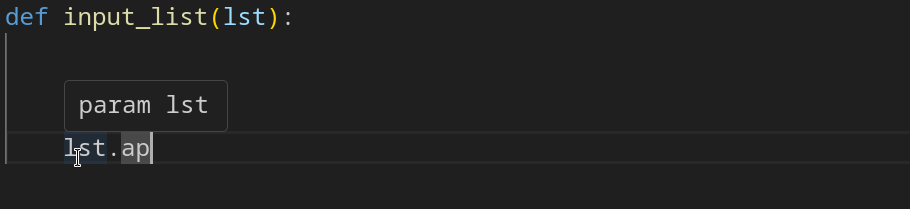
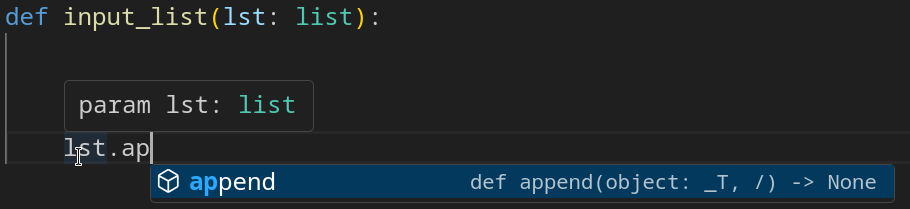

А що як буде список стрічок, і захочеться щось зробити зі стрічкою? Тоді ні майбутні читачі, ні редактор коду не знатимуть, якого типу елементи списку:

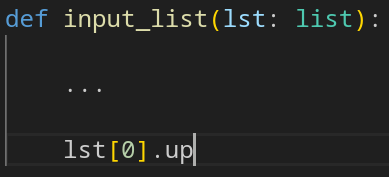

Однак є спосіб таки вказати, що це список саме стрічок. Для цього потрібно використати `list[str]` - у **квадратних** дужках `str` після оголошення, що це список:

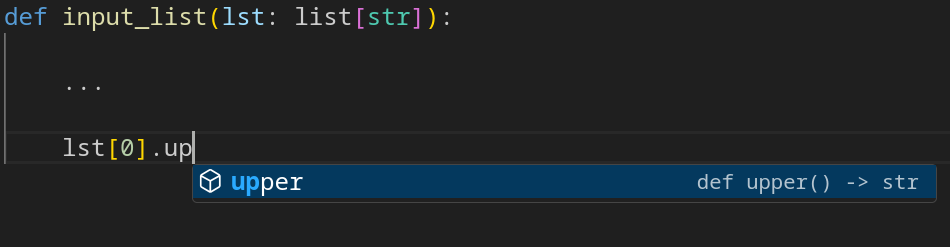

Тепер зрозуміло, що в собі містить список, і редактор тепер може підказати, що існує метод `upper` для стрічок.

Якщо ж буде список зі списків зі стрічок, то можна писати `list[list[str]]`:

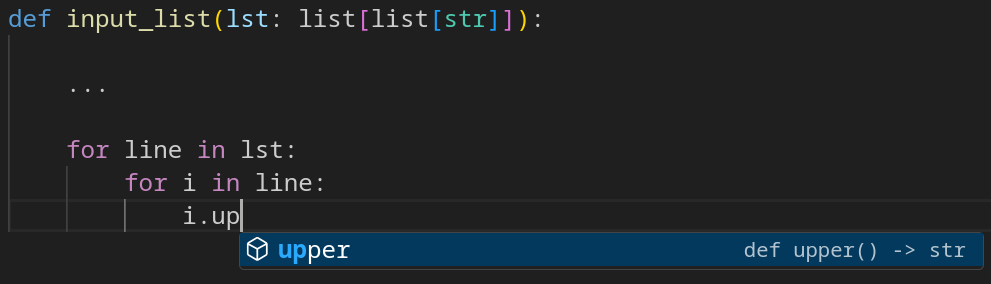

Продовжувати можна довго, хоч навіть `list[list[list[list[list[int]]]]]`. Але я схожий синтаксис і для кортежів. Однак тут він трохи різниця: `tuple[<тип перого елемента>, <тип другого елемента>, ..., <тип останнього>]`

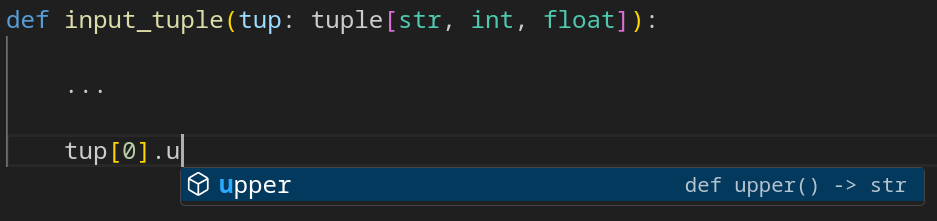

Такі підказки можна поєднувати. Наприклад `list[tuple[str, int]]` є списком кортежів, в кожному з яких першим елементом є стрічка, а другим - ціле число. А `tuple[int, list[str]]` є кортежем, де перший елемент - `int`, а другий - список стрічок.

Такі типи, коли список може приймати як числа, так і стрічки чи щось інше, і ми це відображаємо як `list[int]` чи `list[str]` називають узагальненими, адже `list` узагальнюється для будь-яких типів.

Схожі узагальнені типи є і для множин та словників, і їх розглянемо пізніше.

Насправді, писати такі детальні типи корисно навіть з прагматичної точки зору прямо під час написання коду. Наприклад, уявімо складний тип `list[list[tuple[str, tuple[int, int]]]]`. Написавши цей тип явно, ми можемо набагато краще й швидше зрозуміти, що потрібно зробити for-цикл у for-циклі та брати елемент `1`, аби отримати кортеж з двох чисел. Без явно заданого типу було би набагато складніше розбиратися у чіткому алгоритмі доступу до бажаних елементів.

Тож якщо під час іспиту трапиться складний тип, є велика ймовірність, що після опису цього типу явно через анотацію стане легше виконувати саме завдання.

Чарівного кодування!